# Spotify Music Recommendation System

## Project Overview

This project explores Spotify track information and builds a content-based music recommendation system. It uses audio characteristics such as danceability, energy, acousticness, instrumentalness, loudness, speechiness, tempo, and valence to identify tracks with similar musical profiles.

The workflow follows the stages of data loading, exploratory data analysis (EDA), feature preprocessing, feature scaling, nearest-neighbor search, recommendation generation, and model evaluation.

**Dataset:** `SpotifyFeatures.csv`

**Main tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

> The existing Python code in this notebook has been preserved. Markdown explanations and section structure have been added to make the workflow easier to read and present.


## 1. Importing Required Libraries

The libraries below support the main tasks in this project:

- **Pandas and NumPy:** data loading, manipulation, and numerical operations.
- **Matplotlib and Seaborn:** exploratory visualizations.
- **Scikit-learn:** feature scaling and nearest-neighbor similarity search.

The following cell imports the libraries used in the notebook.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

Load the Spotify features file into a Pandas DataFrame. The first few rows are displayed to inspect the dataset structure and understand the available fields.

Make sure `SpotifyFeatures.csv` is available in the notebook's working directory, or update the file path in the existing code.


In [2]:
df = pd.read_csv('SpotifyFeatures.csv')
df.head()

,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
0,Movie,Henri Salvador,C'est beau de faire un Show,0BRjO6ga9RKCKjfDqeFgWV,0,0.611,0.389,99373,0.910,0.000,C#,0.3460,-1.828,Major,0.0525,166.969,4/4,0.814
1,Movie,Martin & les fées,Perdu d'avance (par Gad Elmaleh),0BjC1NfoEOOusryehmNudP,1,0.246,0.590,137373,0.737,0.000,F#,0.1510,-5.559,Minor,0.0868,174.003,4/4,0.816
2,Movie,Joseph Williams,Don't Let Me Be Lonely Tonight,0CoSDzoNIKCRs124s9uTVy,3,0.952,0.663,170267,0.131,0.000,C,0.1030,-13.879,Minor,0.0362,99.488,5/4,0.368
3,Movie,Henri Salvador,Dis-moi Monsieur Gordon Cooper,0Gc6TVm52BwZD07Ki6tIvf,0,0.703,0.240,152427,0.326,0.000,C#,0.0985,-12.178,Major,0.0395,171.758,4/4,0.227
4,Movie,Fabien Nataf,Ouverture,0IuslXpMROHdEPvSl1fTQK,4,0.950,0.331,82625,0.225,0.123,F,0.2020,-21.150,Major,0.0456,140.576,4/4,0.390


### 2.1 Dataset Dimensions

The shape of the DataFrame reports the number of records (rows) and variables (columns). This gives an initial overview of the dataset's size.


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 232725
Number of Columns: 18


### 2.2 Dataset Information and Data Types

The `info()` output provides the column names, non-null counts, and data types. This helps identify columns that may need cleaning or conversion before analysis.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232725 entries, 0 to 232724
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   genre             232725 non-null  object 
 1   artist_name       232725 non-null  object 
 2   track_name        232724 non-null  object 
 3   track_id          232725 non-null  object 
 4   popularity        232725 non-null  int64  
 5   acousticness      232725 non-null  float64
 6   danceability      232725 non-null  float64
 7   duration_ms       232725 non-null  int64  
 8   energy            232725 non-null  float64
 9   instrumentalness  232725 non-null  float64
 10  key               232725 non-null  object 
 11  liveness          232725 non-null  float64
 12  loudness          232725 non-null  float64
 13  mode              232725 non-null  object 
 14  speechiness       232725 non-null  float64
 15  tempo             232725 non-null  float64
 16  time_signature    23

### 2.3 Missing Value Inspection

Missing values can affect analysis and model preparation. This check identifies columns that contain null values and shows how many values are missing in each.


In [5]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

track_name    1
dtype: int64


### 2.4 Duplicate Records and Unique Tracks

This section checks for exact duplicate rows and counts distinct track IDs. A track may appear in more than one genre entry, so the number of rows and the number of unique tracks may differ.


In [6]:
print("Duplicate Rows:", df.duplicated().sum())

print("Unique Tracks:", df["track_id"].nunique())

Duplicate Rows: 0
Unique Tracks: 176774


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the dataset through summary information and visualizations. The following plots examine genre representation, artist representation, popularity, and selected audio characteristics.

EDA helps us understand the data before selecting and preparing features for the recommendation model.


## Top 10 Music Genres

### 3.1 Top 10 Music Genres

This bar chart displays the ten most frequently represented genres in the dataset. It helps identify which genres have the largest representation.

**How to interpret it:** Longer bars indicate genres with more records. This describes the dataset's composition; it does not necessarily represent overall music-listening popularity.


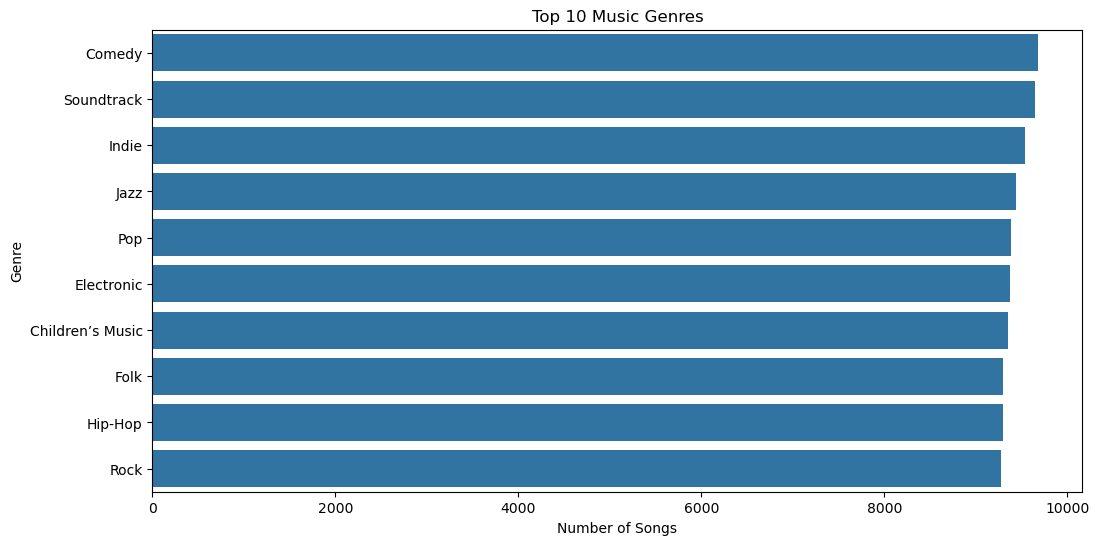

In [7]:
plt.figure(figsize=(12, 6))

top_genres = df["genre"].value_counts().head(10)

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Music Genres")
plt.xlabel("Number of Songs")
plt.ylabel("Genre")

plt.show()

### 3.2 Top 10 Artists by Number of Songs

This visualization identifies the artists with the highest number of records in the dataset.

**How to interpret it:** Artists with longer bars have more tracks represented in this dataset. The result reflects dataset coverage, not necessarily an artist's global popularity.


## Top 10 artists by number of songs

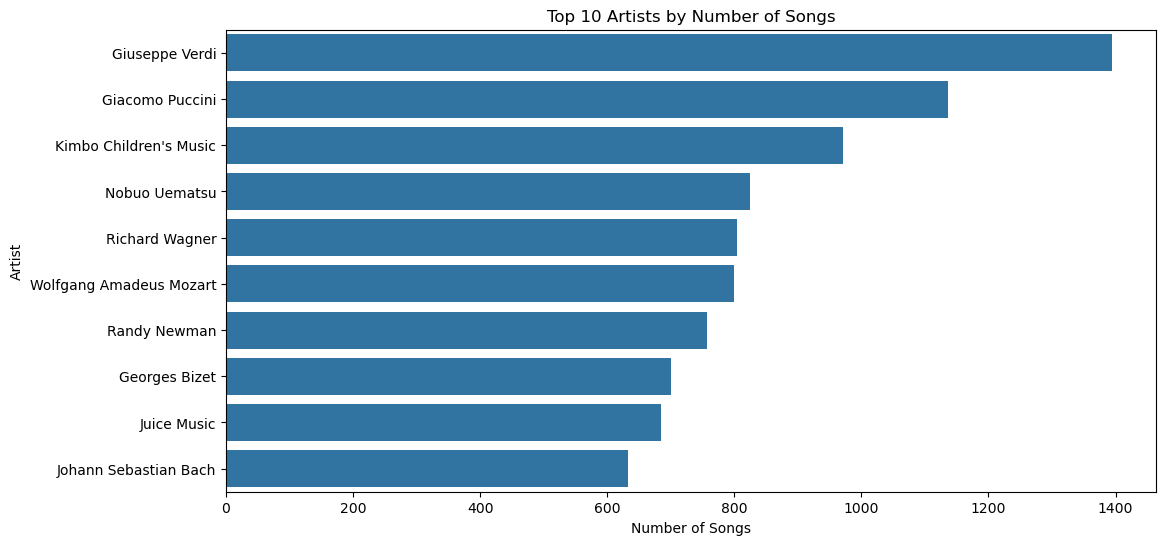

In [8]:
plt.figure(figsize=(12, 6))

top_artists = df["artist_name"].value_counts().head(10)

sns.barplot(
    x=top_artists.values,
    y=top_artists.index
)

plt.title("Top 10 Artists by Number of Songs")
plt.xlabel("Number of Songs")
plt.ylabel("Artist")

plt.show()

### 3.3 Song Popularity Distribution

The histogram shows how track popularity scores are distributed across the dataset. The KDE curve provides a smoothed view of the distribution.

**How to interpret it:** Look for where scores are concentrated, whether the distribution is skewed, and whether there are relatively few tracks at the high or low ends.


## Song popularity distribution

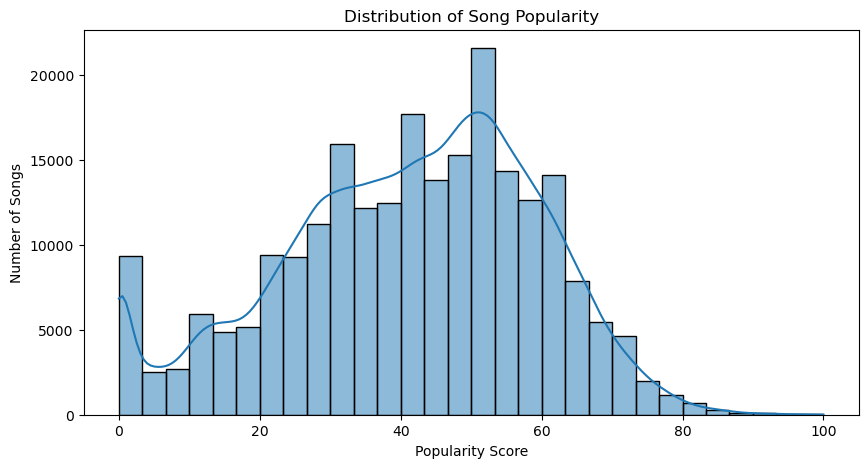

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["popularity"],
    bins=30,
    kde=True
)

plt.title("Distribution of Song Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Songs")

plt.show()

### 3.4 Danceability Distribution

Danceability is an audio feature describing how suitable a track is for dancing. Its score is represented on a scale from 0 to 1.

**How to interpret it:** The histogram shows whether the dataset contains more tracks with lower, moderate, or higher danceability scores.


## Danceability distribution

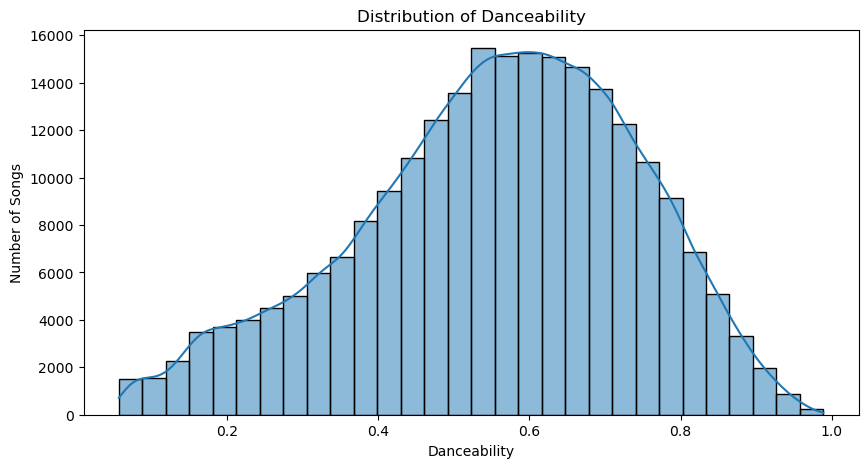

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["danceability"],
    bins=30,
    kde=True
)

plt.title("Distribution of Danceability")
plt.xlabel("Danceability")
plt.ylabel("Number of Songs")

plt.show()

### 3.5 Relationship Between Energy and Danceability

The scatter plot compares energy and danceability for a sample of 5,000 records. Sampling makes the visualization easier to inspect while retaining a reproducible selection through the fixed random state.

**How to interpret it:** Each point represents a track. A visible pattern may suggest an association between energy and danceability, while a diffuse cloud suggests a weaker relationship.


## Energy vs Danceability

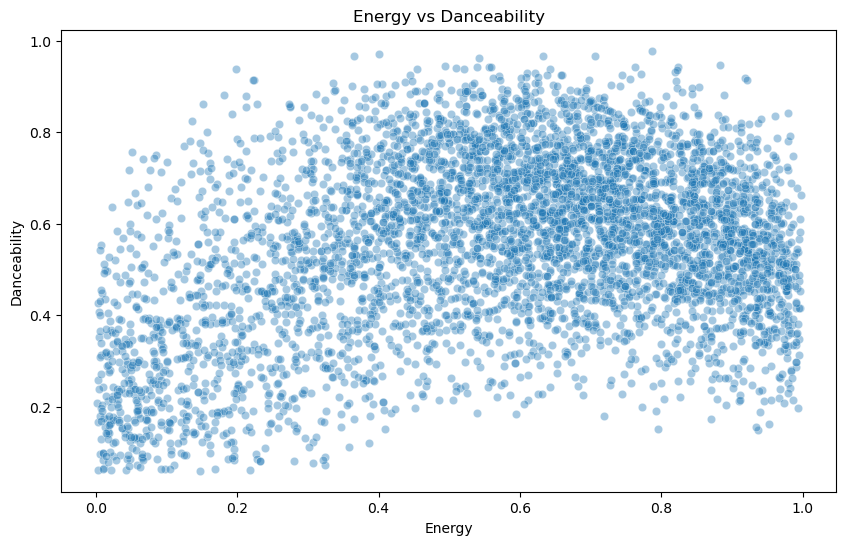

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x="energy",
    y="danceability",
    alpha=0.4
)

plt.title("Energy vs Danceability")
plt.xlabel("Energy")
plt.ylabel("Danceability")

plt.show()

### 3.6 Correlation Between Audio Features

A correlation heatmap summarizes pairwise linear relationships between the selected numerical variables, including popularity.

Correlation values range from -1 to +1:

- **+1:** strong positive linear relationship.
- **0:** little or no linear relationship.
- **-1:** strong negative linear relationship.

Correlation describes association, not causation. The heatmap is an exploratory tool for understanding how the features relate to one another.


## Audio feature correlation

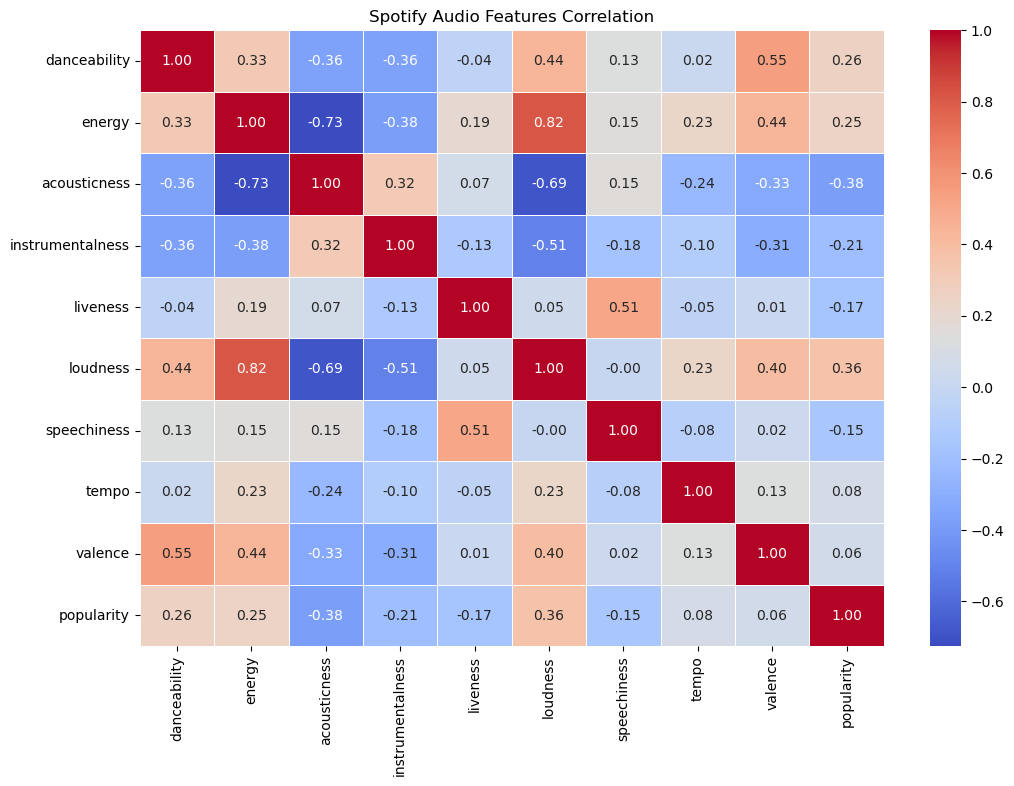

In [12]:
audio_features = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity"
]

plt.figure(figsize=(12, 8))

correlation = df[audio_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Spotify Audio Features Correlation")

plt.show()

## 4. Feature Preprocessing

Feature preprocessing prepares the dataset for the recommendation algorithm. In this project, the model uses numerical audio characteristics to compare tracks.

The steps below select the audio features, inspect and handle missing values, retain one record per track ID, and standardize the selected features.


# Feature Preprocessing

### 4.1 Selecting Audio Features

The selected features describe different aspects of a track's sound. They will be used as input variables for similarity calculations.

The project uses nine audio features: danceability, energy, acousticness, instrumentalness, liveness, loudness, speechiness, tempo, and valence.


### Create a list of audio features

In [13]:
audio_features = [
    'danceability',
    'energy',
    'acousticness',
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'tempo',
    'valence'
]

print("Selected Audio Features:")
print(audio_features)

print("\nTotal Features:", len(audio_features))

Selected Audio Features:
['danceability', 'energy', 'acousticness', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence']

Total Features: 9


### 4.2 Inspecting and Handling Missing Values

First, inspect missing values in the selected audio features. The following code then converts these columns to numeric values and fills missing entries with the median of the corresponding feature.

Using the median provides a simple way to retain rows while filling missing numerical values.


### Handle missing values

In [14]:
print("Missing Values Before Cleaning:\n")

print(df[audio_features].isnull().sum())

Missing Values Before Cleaning:

danceability        0
energy              0
acousticness        0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
dtype: int64


In [15]:
df[audio_features] = df[audio_features].apply(
    pd.to_numeric,
    errors='coerce'
)

df[audio_features] = df[audio_features].fillna(
    df[audio_features].median()
)

print("Missing Values After Cleaning:")
print(df[audio_features].isnull().sum().sum())

Missing Values After Cleaning:
0


### 4.3 Removing Duplicate Tracks

The dataset can contain multiple records associated with the same track ID. For this recommendation workflow, the code retains the first occurrence of each track ID.

This creates `df_model`, the track-level DataFrame used by the recommendation model. The original `df` remains available for the earlier EDA.


### Remove duplicate tracks

In [16]:
print("Before Removing Duplicates:", df.shape)

df_model = df.drop_duplicates(
    subset=['track_id']
).copy()

df_model = df_model.reset_index(drop=True)

print("After Removing Duplicates:", df_model.shape)

print(
    "Unique Track IDs:",
    df_model['track_id'].nunique()
)

Before Removing Duplicates: (232725, 18)
After Removing Duplicates: (176774, 18)
Unique Track IDs: 176774


### 4.4 Feature Scaling Using StandardScaler

The selected audio features use different numerical ranges. For example, tempo is measured in beats per minute, while danceability and energy are bounded scores.

`StandardScaler` standardizes each selected feature by centering it around a mean of approximately zero and scaling it to a standard deviation of approximately one. This helps prevent features with larger numerical ranges from dominating distance calculations solely because of their units.


### Feature scaling using StandardScaler

In [17]:
scaler = StandardScaler()

features_scaled = scaler.fit_transform(
    df_model[audio_features]
)

print("Feature Scaling Completed!")

print("Scaled Features Shape:", features_scaled.shape)

Feature Scaling Completed!
Scaled Features Shape: (176774, 9)


### 4.5 Inspecting the Scaled Features

The scaled NumPy array is converted into a DataFrame so that the standardized feature values can be inspected with familiar column labels.


### Convert scaled features into a DataFrame

In [18]:
scaled_df = pd.DataFrame(
    features_scaled,
    columns=audio_features
)

scaled_df.head()

,danceability,energy,acousticness,instrumentalness,liveness,loudness,speechiness,tempo,valence
0,-0.798733,1.279646,0.564740,-0.532841,0.575611,1.299283,-0.366515,1.588677,1.353170
1,0.257016,0.652467,-0.431708,-0.532841,-0.348444,0.715907,-0.198661,1.813226,1.360637
2,0.640447,-1.544471,1.495668,-0.532841,-0.575904,-0.585001,-0.446282,-0.565544,-0.312134
3,-1.581352,-0.837536,0.815900,-0.532841,-0.597228,-0.319034,-0.430133,1.741558,-0.838608
4,-1.103376,-1.203692,1.490208,-0.151959,-0.106768,-1.721889,-0.400281,0.746124,-0.229989


### 4.6 Verifying Feature Scaling

This check displays the mean and standard deviation of each scaled feature. The means should be close to zero and the standard deviations should be close to one (small display or floating-point differences are normal).


### Verify feature scaling

In [19]:
print("Feature Means:\n")
print(scaled_df.mean().round(2))

print("\nFeature Standard Deviations:\n")
print(scaled_df.std().round(2))

Feature Means:

danceability        0.0
energy             -0.0
acousticness        0.0
instrumentalness    0.0
liveness           -0.0
loudness           -0.0
speechiness        -0.0
tempo              -0.0
valence             0.0
dtype: float64

Feature Standard Deviations:

danceability        1.0
energy              1.0
acousticness        1.0
instrumentalness    1.0
liveness            1.0
loudness            1.0
speechiness         1.0
tempo               1.0
valence             1.0
dtype: float64


## 5. Building the Similarity Search Model

A full pairwise cosine-similarity matrix for a large track collection can require substantial memory. Instead, this notebook uses Scikit-learn's `NearestNeighbors` with the cosine distance metric.

The model is fitted on the standardized audio features. When a track is queried, it finds nearby tracks in the feature space without storing a complete all-by-all similarity matrix.


# Calculate Cosine Similarity

### 5.1 Fit the Nearest Neighbors Model

The model is configured to use cosine distance and brute-force neighbor search. The requested number of neighbors is 11 so that the selected track itself can be returned alongside up to ten other close matches.


In [20]:
from sklearn.neighbors import NearestNeighbors

model = NearestNeighbors(
    metric='cosine',
    algorithm='brute',
    n_neighbors=11,
    n_jobs=-1
)

model.fit(features_scaled)

print("Nearest Neighbors Model Trained Successfully!")

Nearest Neighbors Model Trained Successfully!


### 5.2 Inspecting Nearest Neighbors

This test queries the model using the first track in the prepared dataset.

- `indices` contains the row positions of the nearest tracks.
- `distances` contains the corresponding cosine distances.

The selected track normally appears first with a distance very close to zero. Smaller cosine distances indicate more similar feature vectors.


In [21]:
distances, indices = model.kneighbors(
    features_scaled[0].reshape(1, -1)
)

print("Recommended Song Indices:")
print(indices)

print("\nCosine Distances:")
print(distances)

Recommended Song Indices:
[[     0  20662  49158  44495  43356  34498   6374  50987 119247  33769
   44169]]

Cosine Distances:
[[1.11022302e-16 2.43099615e-02 2.60287195e-02 2.73460961e-02
  3.16728761e-02 3.66751025e-02 3.96584889e-02 4.44562018e-02
  4.55510616e-02 4.57542063e-02 4.74453854e-02]]


## 6. Creating the Music Recommendation Function

The recommendation function accepts a track name, locates the corresponding record, and queries the fitted nearest-neighbor model.

It removes the selected track from the returned results, retrieves the recommended tracks' metadata, and converts cosine distance into a similarity percentage using:

**Similarity (%) = (1 − cosine distance) × 100**

This percentage expresses similarity in the selected audio-feature space; it is not a measure of listener preference.


In [22]:
def recommend_songs(song_name, top_n=10):

    # Find the selected song
    song_match = df_model[
        df_model['track_name'].str.lower() == song_name.lower()
    ]

    if song_match.empty:
        print("Song not found. Please try another song.")
        return

    # Get song index
    song_index = song_match.index[0]

    # Find nearest songs
    distances, indices = model.kneighbors(
        features_scaled[song_index].reshape(1, -1),
        n_neighbors=top_n + 1
    )

    # Remove selected song
    recommended_indices = indices[0][1:]
    recommended_distances = distances[0][1:]

    # Create recommendation DataFrame
    recommendations = df_model.iloc[
        recommended_indices
    ][['track_name', 'artist_name', 'genre', 'popularity']].copy()

    # Calculate similarity percentage
    recommendations['Similarity Score'] = (
        (1 - recommended_distances) * 100
    ).round(2)

    print(f"\nSongs similar to: {song_name}\n")

    return recommendations.reset_index(drop=True)

### 6.1 Testing the Recommendation Function

The following cell tests the function with a track name from the dataset and requests ten recommendations. Review the returned track names, artists, genres, popularity values, and similarity scores.


In [23]:
recommend_songs("Don't Let Me Be Lonely Tonight", top_n=10)


Songs similar to: Don't Let Me Be Lonely Tonight



,track_name,artist_name,genre,popularity,Similarity Score
0,Everything Is Free,Gillian Welch,Country,48,99.59
1,I Am Trying to Break Your Heart,Jeff Tweedy,Folk,45,99.22
2,This Must Be The Place (Naïve Melody),The Lumineers,Folk,52,99.09
3,Kind Woman,Buffalo Springfield,Country,45,99.07
4,Waiting,Norah Jones,Folk,52,98.99
5,How Does A Moment Last Forever (Music Box) - Demo,Alan Menken,Movie,41,98.97
6,Satin Doll,Ella Fitzgerald,Jazz,43,98.95
7,When I Grow Too Old To Dream - Remastered 1999,Nat King Cole,Jazz,38,98.88
8,Heaven Is a Place on Earth,The Mayries,Indie,55,98.81
9,Calling Out To You,Tedeschi Trucks Band,Blues,43,98.71


### 6.2 Recommendation Function with Selected Track Details

This version of the recommendation function also displays the selected track's title, artist, and genre before returning the recommendations. It retains the same nearest-neighbor approach.


In [24]:
def recommend_songs(song_name, top_n=10):

    song_match = df_model[
        df_model['track_name'].str.lower() == song_name.lower()
    ]

    if song_match.empty:
        print("Song not found.")
        return

    song_index = song_match.index[0]

    selected_song = df_model.iloc[song_index]

    distances, indices = model.kneighbors(
        features_scaled[song_index].reshape(1, -1),
        n_neighbors=top_n + 1
    )

    recommended_indices = indices[0][1:]
    recommended_distances = distances[0][1:]

    recommendations = df_model.iloc[
        recommended_indices
    ][
        ['track_name', 'artist_name', 'genre', 'popularity']
    ].copy()

    recommendations['Similarity Score'] = (
        (1 - recommended_distances) * 100
    ).round(2)

    print("Selected Song:", selected_song['track_name'])
    print("Artist:", selected_song['artist_name'])
    print("Genre:", selected_song['genre'])

    return recommendations.reset_index(drop=True)

## 7. Model Evaluation and Recommendation Inspection

The following checks provide simple diagnostics for the recommendation results. They examine genre consistency and average similarity for one selected track.

These are exploratory evaluation measures rather than a complete assessment of user satisfaction. A recommendation can be musically similar according to the selected audio features without necessarily matching a listener's personal taste.


In [25]:
def evaluate_recommendations(song_name, top_n=10):

    song = df_model[
        df_model['track_name'].str.lower() == song_name.lower()
    ]

    if song.empty:
        print("Song not found!")
        return

    original_genre = song.iloc[0]['genre']

    recommendations = recommend_songs(song_name, top_n)

    genre_matches = (
        recommendations['genre'] == original_genre
    ).sum()

    genre_percentage = (genre_matches / top_n) * 100

    avg_similarity = recommendations[
        'Similarity Score'
    ].mean()

    print("\n--- MODEL EVALUATION ---")

    print("Original Genre:", original_genre)

    print("Genre Matches:", genre_matches, "/", top_n)

    print("Genre Consistency:", round(genre_percentage, 2), "%")

    print("Average Similarity:", round(avg_similarity, 2), "%")

### 7.1 Evaluate Genre Consistency and Average Similarity

The evaluation compares each recommended track's genre with the selected track's genre and calculates the average similarity score.

Genre consistency is a strict same-label comparison. It should be interpreted carefully because tracks with different genre labels can still have similar audio characteristics.


In [26]:
evaluate_recommendations(
    "Don't Let Me Be Lonely Tonight",
    top_n=10
)

Selected Song: Don't Let Me Be Lonely Tonight
Artist: Joseph Williams
Genre: Movie

--- MODEL EVALUATION ---
Original Genre: Movie
Genre Matches: 1 / 10
Genre Consistency: 10.0 %
Average Similarity: 99.03 %


### 7.2 Compare Audio Features of the Selected and Recommended Tracks

This section gathers the original, unscaled audio feature values for the selected track and its ten nearest recommendations.

The resulting table makes it possible to inspect the actual feature values rather than only the combined similarity score.


In [27]:
song_name = "Don't Let Me Be Lonely Tonight"

song_index = df_model[
    df_model['track_name'].str.lower() == song_name.lower()
].index[0]

distances, indices = model.kneighbors(
    features_scaled[song_index].reshape(1, -1),
    n_neighbors=11
)

recommended_indices = indices[0][1:]

comparison_indices = [song_index] + list(recommended_indices)

comparison_df = df_model.iloc[
    comparison_indices
][audio_features].copy()

comparison_df.index = [
    "Selected Song"
] + [
    f"Recommended {i}" for i in range(1, 11)
]

comparison_df.head(11)

,danceability,energy,acousticness,instrumentalness,liveness,loudness,speechiness,tempo,valence
Selected Song,0.663,0.131,0.952,0.000000,0.1030,-13.879,0.0362,99.488,0.368
Recommended 1,0.686,0.143,0.940,0.000077,0.0792,-14.701,0.0420,101.651,0.351
Recommended 2,0.670,0.188,0.889,0.000025,0.0929,-14.122,0.0582,104.908,0.328
Recommended 3,0.636,0.220,0.808,0.000000,0.1120,-12.416,0.0269,98.492,0.377
Recommended 4,0.687,0.194,0.934,0.000491,0.1380,-13.177,0.0300,105.278,0.344
Recommended 5,0.675,0.175,0.865,0.009200,0.1060,-14.548,0.0310,93.786,0.403
Recommended 6,0.710,0.161,0.960,0.000393,0.1140,-12.924,0.0418,95.943,0.409
Recommended 7,0.609,0.131,0.893,0.000000,0.1020,-12.354,0.0369,98.896,0.383
Recommended 8,0.693,0.127,0.865,0.000000,0.1300,-13.844,0.0464,106.867,0.349
Recommended 9,0.634,0.176,0.931,0.000002,0.1360,-14.703,0.0308,107.873,0.336


### 7.3 Visualize Audio Feature Comparisons

The bar chart compares the selected track's audio features with those of the recommended tracks.

Because the chart uses original feature values, the features have different scales. Use it to inspect individual feature patterns, while remembering that the recommendation model calculated distances using standardized values.


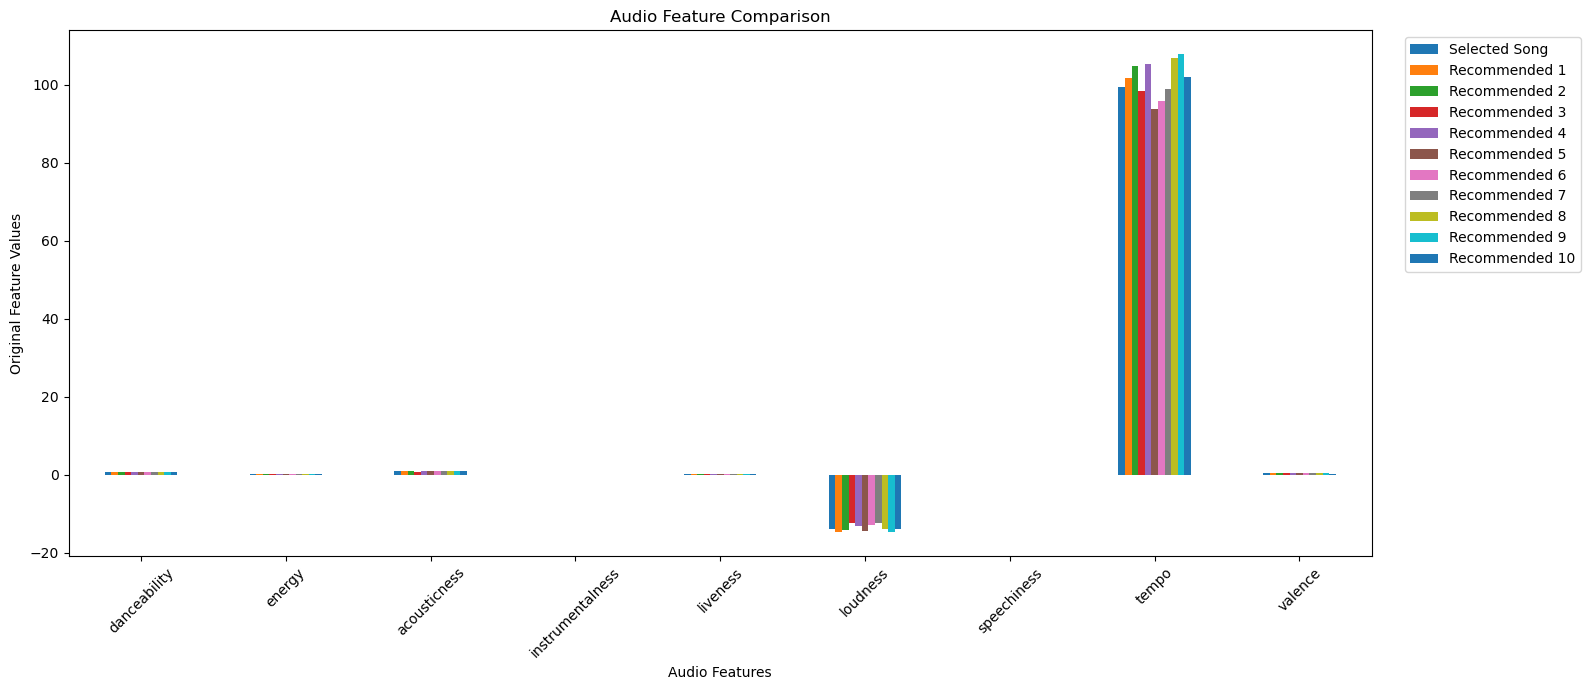

In [28]:
comparison_df.T.plot(
    kind='bar',
    figsize=(16, 7)
)

plt.title("Audio Feature Comparison")
plt.xlabel("Audio Features")
plt.ylabel("Original Feature Values")
plt.xticks(rotation=45)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

## 8. Streamlit Application

The final section contains the Streamlit application source. It is written to a Python file using the notebook's existing cell magic.

The application loads the Spotify CSV, prepares the audio features, fits a nearest-neighbor model, and provides a song search interface for displaying recommendations.

To run the resulting application, ensure the CSV file is in the expected working directory and run the generated Python script with Streamlit from a terminal.


In [29]:
%%writefile Spotify.py
import streamlit as st
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# -----------------------------
# PAGE CONFIGURATION
# -----------------------------

st.set_page_config(
    page_title="Spotify Music Recommender",
    page_icon="🎵",
    layout="wide"
)

# -----------------------------
# CUSTOM DESIGN
# -----------------------------

st.markdown("""
<style>
.stApp {
    background-color: #121212;
    color: white;
}

h1, h2, h3, p, label {
    color: white !important;
}

.stButton button {
    background-color: #1DB954;
    color: white;
    border-radius: 20px;
    border: none;
    font-weight: bold;
}

.song-card {
    background-color: #222222;
    padding: 18px;
    border-radius: 12px;
    margin-bottom: 12px;
}
</style>
""", unsafe_allow_html=True)

# -----------------------------
# AUDIO FEATURES
# -----------------------------

audio_features = [
    'danceability',
    'energy',
    'acousticness',
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'tempo',
    'valence'
]

# -----------------------------
# LOAD DATA AND MODEL
# -----------------------------

@st.cache_resource
def load_model():

    df = pd.read_csv("SpotifyFeatures.csv")

    df = df.dropna(
        subset=['track_id', 'track_name', 'artist_name']
    )

    df = df.drop_duplicates(
        subset=['track_id']
    ).reset_index(drop=True)

    for col in audio_features:
        df[col] = pd.to_numeric(
            df[col], errors='coerce'
        )

        df[col] = df[col].fillna(df[col].median())

    scaler = StandardScaler()

    features_scaled = scaler.fit_transform(
        df[audio_features]
    )

    model = NearestNeighbors(
        metric='cosine',
        algorithm='brute',
        n_neighbors=11,
        n_jobs=-1
    )

    model.fit(features_scaled)

    return df, features_scaled, model


df, features_scaled, model = load_model()

# -----------------------------
# APPLICATION HEADER
# -----------------------------

st.title("🎵 Spotify Music Recommender")

st.write(
    "Discover songs based on their musical characteristics."
)

st.divider()

# -----------------------------
# SEARCH SONG
# -----------------------------

st.subheader("Find Your Favourite Song")

song_name = st.text_input(
    "Enter Song Name",
    placeholder="Search for a song..."
)

if song_name:

    matches = df[
        df['track_name'].str.contains(
            song_name,
            case=False,
            na=False,
            regex=False
        )
    ]

    if matches.empty:

        st.warning("No matching songs found.")

    else:

        options = {
            f"{row.track_name} — {row.artist_name}": row.Index
            for row in matches.itertuples()
        }

        selected_song = st.selectbox(
            "Select a song",
            list(options.keys())
        )

        if st.button("Recommend Songs"):

            song_index = options[selected_song]

            song = df.iloc[song_index]

            st.success(
                f"Recommendations for {song['track_name']}"
            )

            col1, col2, col3 = st.columns(3)

            col1.metric("Artist", song['artist_name'])
            col2.metric("Genre", song['genre'])
            col3.metric("Popularity", song['popularity'])

            distances, indices = model.kneighbors(
                features_scaled[song_index].reshape(1, -1),
                n_neighbors=11
            )

            recommended_indices = indices[0][1:]
            recommended_distances = distances[0][1:]

            recommendations = df.iloc[
                recommended_indices
            ][
                ['track_name', 'artist_name', 'genre', 'popularity']
            ].copy()

            recommendations['Similarity'] = (
                (1 - recommended_distances) * 100
            ).round(2)

            st.divider()
            st.subheader("🎧 Recommended Songs")

            st.dataframe(
                recommendations.reset_index(drop=True),
                use_container_width=True,
                hide_index=True
            )

# -----------------------------
# FOOTER
# -----------------------------

st.divider()

st.caption(
    "Built using Python, Pandas, Scikit-learn and Streamlit."
)


Writing Spotify.py


## 9. Project Conclusion

This notebook demonstrates a content-based music recommendation workflow using Spotify track audio features.

The project covers:

1. Loading and inspecting the Spotify dataset.
2. Exploring genre, artist, popularity, and audio-feature distributions.
3. Selecting and preprocessing numerical audio features.
4. Standardizing features with `StandardScaler`.
5. Finding similar tracks with cosine distance and `NearestNeighbors`.
6. Generating track recommendations and inspecting their genre and audio-feature characteristics.
7. Providing a Streamlit interface for interactive recommendations.

### Limitations and Future Improvements

- The recommendations are based on the nine selected audio features and do not use lyrics, listening history, or user feedback.
- Similarity scores indicate proximity in the standardized feature space; they should not be interpreted as a guarantee that a listener will like a track.
- Genre labels can be broad or inconsistent, so genre consistency is only a basic diagnostic.
- Future improvements could include user feedback, genre-aware filtering, recommendation diversity, track artwork, and links to official streaming pages.

**Outcome:** A content-based Spotify music recommendation prototype built with Python and Scikit-learn.
